# Limitation 2 — The scan law

**The directions and the epochs of the windows are not chosen; the scan law gives them. Gaia scans a given star in bundles of nearly one direction, and the bundles come at particular epochs. No atom assumes anything about the law, and every one of them is worse on a clumped law than on an even one.**

Every limitation notebook has the same four parts. **The premise** states
what the atoms assume and shows the case that breaks it. Then **one section
per atom**, always in the same order, the two images of the windows, the map
of detections, the joint fit, each answering three questions: what does this
atom assume here, what does it return in this case, and does it warn you.
**The summary table** closes with the same columns every time: atom, effect,
alarm, remedy.

The case of this page: the public Gaia forecast for the Pleiades center, its first 40 scan angles and epochs, against 40 and 80 directions spread evenly over the half-turn. The pair is the control pair, 200 mas at position angle 110°; a closer pair, 60 mas, where it matters.

| block | task | calls | paper |
|---|---|---|---|
| setup | the toy instrument, the helpers, the three sets of directions | `ins.Instrument.gaussian`, `ins.render_window`, `sim.simulate_window`, `joint.scene_positions_al` | Sect. 2.1, Eqs. 3–4 |
| 1 | the premise: the largest gap and the anisotropy of a set of directions | (numpy only) | App. B.2; Sect. 4.4 |
| 2 | the two images, and faststack's α | `radon.filtered_backprojection`, `radon.faststack`, `ins.render_window` | App. C.2, Eq. C.3, Fig. C.1 |
| 3 | the map of detections, and the windows that resolve the pair | `bp.map_peak`, `bp.backprojection_map` | Sect. 3.3, Eq. 13; Fig. C.1 |
| 4 | the joint fit's covariance, static and moving | `joint.joint_fisher`, `joint.joint_covariance` | Sect. 4.3, Eq. 18; App. B.2, Eq. B.9; App. B.3, Eq. B.13 |

Every scanlib call carries the name of its module (`joint.fit_joint`); the first code cell lists the modules.

**The series.** The three images and the fit are in [`../00_three_images_and_fit.ipynb`](../00_three_images_and_fit.ipynb). The limitations: [1 — the finite window](01_finite_window.ipynb), this page, [3 — one line, two lines, three](03_few_lines.ipynb), [4 — a scene that moves](04_motion.ipynb), [5 — the blend](05_blend.ipynb), [6 — errors of the model, and the noise](06_model_errors.ipynb).

**Symbols and units** are defined once for the package and every notebook in [`docs/conventions.md`](../../../docs/conventions.md). This page uses ψ, η, τ and μ, θ, σ_η and the detections, the map, the Fisher σ and ellipse, faststack and α, R and the largest gap, and the laws.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import backprojection as bp   # the triangulation map and its peak
from scanlib import radon                  # the inverse Radon transform and faststack
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# the paper's figure style: font 10, ticks 9 and inward, thin axes; grays first, one accent
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 7.5})
ACCENT = "tomato"                                          # the one accent
# the markers: each name below in capitals with dict(...) is a table of the keywords that ax.scatter takes for
# one kind of point
TRUTH = dict(marker="*", s=150, facecolor="white", edgecolor="k", lw=0.8, zorder=7)   # the truth
SEED = dict(marker="o", s=60, facecolor="none", edgecolor=ACCENT, lw=1.1, zorder=6)  # a starting point (the map's peak)
# the labels of the two sky axes
EAST = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)"
NORTH = r"$\Delta\delta$  [mas]"


def letter(ax, label, text=""):
    """Write a panel's letter, bold, inside the panel's top-left corner, and a few words after it.

    Inputs
        ax      the panel (a matplotlib Axes)
        label   the panel's letter, for example "a"
        text    the words after the letter (default: none)
    Returns nothing: the letter and the words are drawn on ax, on a white box that dims what is under them."""
    white_box = dict(fc="white", ec="none", pad=1.0, alpha=0.8)
    ax.text(0.04, 0.96, rf"$\bf{{({label})}}$ " + text, transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=white_box)

In [3]:
# the toy instrument, the noise, the pair's position angle and fluxes, the two sets of scan directions, and the
# sky grid of every image
FWHM = 100.0                                 # the LSF's full width at half maximum [mas]
# The instrument, defined once: 18 samples 59 mas apart, a Gaussian LSF of
# that FWHM, and the trial positions of the per-window reduction.
inst = ins.Instrument.gaussian(fwhm_mas=FWHM, pitch_mas=59.0, n_samples=18)
grid = inst.sample_grid_mas                  # sample centers along the scan [mas]
pitch = grid[1] - grid[0]                    # the distance between two neighboring samples: 59 mas
sigma_lsf = FWHM / (2.0 * np.sqrt(2.0 * np.log(2.0)))   # LSF sigma [mas], for the formulas
sigma_noise = 10.0                           # the noise sigma of one sample; the primary's total flux is 100 sigma
pa = np.deg2rad(110.0)                       # the pair's position angle [rad], counter-clockwise from north
flux = np.array([1000.0, 200.0])             # the fluxes of the primary and of the companion, in the windows' units
EVEN = np.linspace(0.0, np.pi, 80, endpoint=False) + 0.01     # 80 even directions [rad]
# ref: the reference cases of the package's tests, a table from a case's name to its array; two of its inputs
# are used here
ref = np.load("../../../tests/reference/reference_cases.npz")
GAIA = ref["static_pair/inputs/psi"]                           # the Gaia forecast's 40 scan angles [rad]
GAIA_TAU = ref["moving_pair/inputs/tau"]                       # and epochs [yr]
half = 400.0                                 # the sky grid of every image: half the side of the square [mas]
step = 4.0                                   # and the size of one pixel [mas]
# degrees of freedom of a static two-source fit on 80 windows: 80 x 18 samples, minus the companion's two
# coordinates and the two fluxes
DOF = EVEN.size * grid.size - 4

In [4]:
# helper: the companion's sky offset at a separation on the pair axis
def pair(rho):
    """The companion's sky offset at a separation on the pair axis (the direction of position angle pa).

    Inputs
        rho   the companion's separation from the primary [mas]
    Returns
        the companion's (dra*, ddec) [mas] from the primary, an array of two numbers"""
    pair_axis = np.array([np.sin(pa), np.cos(pa)])            # the unit vector of the pair axis, (dra*, ddec)
    return rho * pair_axis

In [5]:
# helper: the windows of a scene, noise-free or noisy (ins.render_window, sim.simulate_window)
def windows_of(theta, psi, flux=flux, tau=None, rng=None, present=None, eta0=None, inst=inst):
    """The windows of a scene, one per scan: noise-free (a formula), or with one draw of noise each.

    Inputs
        theta     the companions' parameters, one flat array: (dra*, ddec) [mas] per companion for a static scene,
                  (dra*, ddec [mas], mu_alpha*, mu_delta [mas/yr]) per companion for a moving one. The primary is
                  at the origin and has no entry
        psi       the scan angle of each of the J windows [rad]
        flux      the flux of each of the K sources, in the windows' units, the primary first
        tau       the epoch of each window [yr] for a moving scene (None: a static scene)
        rng       the random generator of the noise, of sigma_noise per sample (None: noise-free windows)
        present   J rows of K booleans: which source is in which window (None: every source in every window)
        eta0      the zero point of each window [mas] (None: every zero point is 0)
        inst      the instrument that renders the windows (default: the page's instrument)
    Returns
        the windows, an array of J rows of N samples, flux per sample"""
    # step 1, the along-scan position of every source in every window [mas]: one row per window, one column per
    # source, the primary first. Each window's zero point is subtracted from its row; [:, None] turns the J zero
    # points into a column, so that row j gets eta0[j]
    eta = joint.scene_positions_al(theta, psi, tau)
    if eta0 is not None:
        eta = eta - np.asarray(eta0)[:, None]

    # step 2, one window per scan; j counts the windows
    windows = []
    for j, eta_j in enumerate(eta):
        # the fluxes in window j: present[j] holds one True or False per source, and a source that is not in
        # the window gets flux 0
        if present is None:
            flux_j = flux
        else:
            flux_j = flux * present[j]
        # the samples of window j: the noise-free model, or the model plus one draw of noise from rng
        if rng is None:
            window = ins.render_window(eta_j, flux_j, inst)
        else:
            window = sim.simulate_window(eta_j, flux_j, inst, rng, sigma_noise)
        windows.append(window)
    return np.array(windows)

In [6]:
# helper, a stand-in for the per-window reduction: the Fisher error of each companion's position in one window
def sigma_eta(eta, flux=flux, sigma_noise=sigma_noise):
    """The Fisher error of each companion's along-scan position in one window, with every flux free. It is a
    formula, not a fit: it stands in for the error that the per-window reduction would report.

    Inputs
        eta           the along-scan position of each of the K sources in the window [mas], the primary first
        flux          the flux of each of the K sources, in the windows' units, the primary first
        sigma_noise   the noise sigma of one sample, in the windows' units
    Returns
        the 1-sigma error of each companion's position [mas], K - 1 numbers (the primary's position is not a
        parameter); every one is infinite where the Fisher matrix is singular"""
    # step 1, the model of the window. columns[:, k] is the window of source k alone at flux 1, one number per
    # sample; derivatives[:, k] is the derivative of that column with respect to the position of source k [1/mas]
    columns = inst.design_columns(eta)
    derivatives = inst.design_jacobian(eta)

    # step 2, the derivative of the window with respect to every parameter, one column each: first the
    # companions' positions ([:, 1:] omits the primary's column and flux[1:] the primary's flux), then the K fluxes
    jacobian = np.column_stack([derivatives[:, 1:] * flux[1:], columns])

    # step 3, the Fisher matrix for Gaussian noise of known sigma. Where its condition number is above 1e12 it
    # cannot be inverted safely: the companions' positions are then not measured in this window
    fisher = jacobian.T @ jacobian / sigma_noise ** 2
    n_companions = eta.size - 1
    if np.linalg.cond(fisher) > 1e12:
        return np.full(n_companions, np.inf)

    # step 4, the errors: the square roots of the diagonal of the inverse. [:n_companions] keeps the positions'
    # entries and omits the fluxes'
    covariance = np.linalg.inv(fisher)
    return np.sqrt(np.diag(covariance)[:n_companions])

In [7]:
# helper, the stand-in's detections: the truth plus one draw of that error, where the error is below 30 mas
def detections(theta, psi, flux=flux, tau=None, sigma_max=30.0, rng=None, present=None):
    """The teaching detections of a scene, a stand-in for the per-window reduction: no window is simulated and no
    window is fitted. A detection is a companion's true along-scan position in a window plus one Gaussian draw of
    its Fisher error there (sigma_eta, at the page's noise sigma_noise).

    Inputs
        theta       the companions' parameters, one flat array, as in windows_of
        psi         the scan angle of each of the J windows [rad]
        flux        the flux of each of the K sources, in the windows' units, the primary first
        tau         the epoch of each window [yr] for a moving scene (None: a static scene)
        sigma_max   a companion gives a detection in a window only where its Fisher error is finite and at most
                    this [mas]
        rng         the random generator of the draws (None: a new generator of seed 8 at every call)
        present     J rows of K booleans: which source is in which window (None: every source in every window);
                    a companion gives no detection in a window that it is not in
    Returns three arrays, one entry per detection
        psi     the scan angle of the detection's window [rad]
        eta     the detected along-scan position [mas]: the truth plus the draw
        sigma   the 1-sigma error of that position [mas]"""
    # step 1, the generator of the detections' errors. The default is a new generator of seed 8 at every call,
    # so two calls for the same scene give the same draws (why 8: not stated)
    if rng is None:
        rng_detections = np.random.default_rng(8)
    else:
        rng_detections = rng

    # step 2, the true along-scan position of every source in every window [mas]: row j is window j, column 0
    # the primary
    eta_true = joint.scene_positions_al(theta, psi, tau)

    # step 3, one detection per window and companion that passes the two tests. j counts the windows; c counts
    # the sources of a window from 1, because source 0 is the primary and gives no detection
    detected_psi = []
    detected_eta = []
    detected_sigma = []
    for j, psi_j in enumerate(psi):
        eta_j = eta_true[j]
        sigma_j = sigma_eta(eta_j, flux)                       # the Fisher error of each companion in window j
        for c in range(1, eta_j.size):
            sigma = sigma_j[c - 1]                             # sigma_j has no entry for the primary
            if present is not None and not present[j, c]:
                continue
            if np.isfinite(sigma) and sigma <= sigma_max:
                error_draw = rng_detections.normal(0.0, sigma)
                detected_psi.append(psi_j)
                detected_eta.append(eta_j[c] + error_draw)
                detected_sigma.append(sigma)
    return np.array(detected_psi), np.array(detected_eta), np.array(detected_sigma)

In [8]:
# helper: the points of a covariance ellipse
def ellipse(cov, center, n_sigma=1.0):
    """The outline of a covariance ellipse on the sky, as points to plot.

    Inputs
        cov       the 2 x 2 covariance of a position (dra*, ddec) [mas^2]
        center    the center of the ellipse, (dra*, ddec) [mas]
        n_sigma   the size of the ellipse, its Mahalanobis radius (1: the 1-sigma ellipse)
    Returns
        200 points around the ellipse, one row (dra*, ddec) [mas] per point; the last point repeats the first"""
    # step 1, the ellipse's axes: the eigenvalues are the variances along them [mas^2], the columns of
    # eigenvectors are their directions
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    # step 2, the unit circle at 200 angles around the full turn: row 0 holds the cosines, row 1 the sines
    angles = np.linspace(0, 2 * np.pi, 200)
    unit_circle = np.vstack([np.cos(angles), np.sin(angles)])

    # step 3, the circle stretched to the ellipse's semi-axes ([:, None] makes them a column: one factor per
    # row of the circle), turned to the axes' directions, and moved to the center. .T gives one row per point
    semi_axes = n_sigma * np.sqrt(eigenvalues)[:, None]
    stretched = semi_axes * unit_circle
    turned = eigenvectors @ stretched
    return turned.T + center

In [9]:
# helper: draw one sky image or map, east to the left, with the sources marked
def show(ax, image, axis, title, marks=None, **imshow_options):
    """Draw one sky image or map, east to the left, with the sources marked by plus signs.

    Inputs
        ax               the panel (a matplotlib Axes)
        image            the image or the map, M rows of M pixels: the rows are ddec, the columns dra*
        axis             the sky coordinate of the M rows, and of the M columns [mas]
        title            the panel's title
        marks            the sources to mark, one row (dra*, ddec) [mas] each (None: the primary at the origin and
                         the companion of this page, the global theta)
        imshow_options   keywords for ax.imshow, for example vmax, the value drawn black
    Returns
        the drawn image (matplotlib's AxesImage)"""
    # step 1, the defaults of the picture, used where the call names no other: white at 0 and black at the
    # highest value, and every pixel drawn as it is (no smoothing)
    imshow_options.setdefault("cmap", "gray_r")
    imshow_options.setdefault("vmin", 0.0)
    imshow_options.setdefault("interpolation", "nearest")

    # step 2, the picture: row 0 at the bottom (north up); axis[0] and axis[-1] are the first and the last
    # coordinate, given as the picture's left and right, and bottom and top
    extent = (axis[0], axis[-1], axis[0], axis[-1])
    drawn_image = ax.imshow(image, origin="lower", extent=extent, **imshow_options)

    # step 3, the plus signs: column 0 of the marks is dra*, column 1 is ddec
    if marks is None:
        marked_sources = np.vstack([[0.0, 0.0], theta])
    else:
        marked_sources = marks
    ax.scatter(marked_sources[:, 0], marked_sources[:, 1], marker="+", s=70, color=ACCENT, lw=1.1, zorder=6)

    # step 4, the title, the label, and the direction of the horizontal axis
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(EAST)
    ax.set_aspect("equal")
    ax.set_xlim(axis[-1], axis[0])                               # east to the left
    return drawn_image

In [10]:
# helper: one printed line that compares a fit with the truth
def report(name, fit, truth, dof):
    """Print one line that compares a joint fit with the truth.

    Inputs
        name    the words that open the line
        fit     the result of joint.fit_joint, a table from a name to a value. Four entries are read:
                fit["theta"] the fitted parameters, fit["sigma_theta"] their Fisher 1-sigma errors, fit["flux"]
                the fitted fluxes (the primary first) and fit["chi2"]
        truth   the true parameters, in the order and the units of fit["theta"]
        dof     the degrees of freedom of the fit
    Returns nothing. The printed line holds: fit - truth for every parameter; the pulls (fit - truth over the
    Fisher sigma); the fluxes of the first two sources; chi2 / dof."""
    difference = fit["theta"] - np.asarray(truth)
    pulls = difference / fit["sigma_theta"]
    # the numbers as text, joined by commas (a short comprehension: one piece of text per parameter)
    difference_text = ", ".join(f"{value:6.2f}" for value in difference)
    pulls_text = ", ".join(f"{value:5.1f}" for value in pulls)
    primary_flux = fit["flux"][0]
    companion_flux = fit["flux"][1]
    chi2_per_dof = fit["chi2"] / dof
    print(f"{name:40s} fit − truth ({difference_text})   pulls ({pulls_text})"
          f"   fluxes {primary_flux:.0f}, {companion_flux:.0f}   chi2/dof {chi2_per_dof:.2f}")

In [11]:
# the page's case: the control pair, and the three sets of directions. EVEN[::2] keeps every second of the 80
# even directions
theta = pair(200.0)                                           # the companion's (dra*, ddec) [mas]
EVEN40 = EVEN[::2]
# LAWS: a table of one row per set of directions; a row holds the set's name and its scan angles [rad]
LAWS = (("80 even directions", EVEN), ("40 even directions", EVEN40), ("Gaia forecast, 40 windows", GAIA))

In [12]:
# helper: the largest gap of a set of directions on the half-turn
def largest_gap(psi):
    """The widest range of directions that holds no window, on the half-turn. A scan direction is a line: psi and
    psi + 180 deg are the same direction.

    Inputs
        psi   the scan angle of each of the J windows [rad]
    Returns
        the largest gap between two neighboring directions [deg]"""
    # step 1, the directions folded into the half-turn (0 to 180 deg), in increasing order
    directions = np.sort(np.mod(psi, np.pi))

    # step 2, the gaps between neighbors. np.r_ appends the first direction plus 180 deg, so that the gap from
    # the last direction round to the first is counted too
    directions_closed = np.r_[directions, directions[0] + np.pi]
    gaps = np.diff(directions_closed)
    return np.degrees(gaps.max())

In [13]:
# helper: the anisotropy R of a set of directions, and the direction of its dominant bundle
def anisotropy(psi):
    """The anisotropy R of a set of scan directions, and the direction of its dominant bundle. R is the length
    of the mean of exp(2 i psi): 0 for directions spread evenly over the half-turn, 1 for directions that are all
    the same. The factor 2 makes psi and psi + 180 deg the same direction.

    Inputs
        psi   the scan angle of each of the J windows [rad]
    Returns two numbers
        R           the anisotropy, from 0 to 1
        direction   the direction of the dominant bundle [deg, modulo 180]"""
    # the mean is a complex number: its length is R, and its phase is twice the dominant direction
    mean_vector = np.mean(np.exp(2j * psi))
    R = abs(mean_vector)
    direction = np.degrees(np.angle(mean_vector) / 2) % 180
    return R, direction

In [14]:
# helper: the map's peak and the two half-widths of the region above half the peak (bp.map_peak)
def peak_axes(psi, eta, sigma, half_size=300.0):
    """The peak of the detections' map, and the two half-widths of the map's region above half its maximum.

    Inputs
        psi, eta, sigma   the detections, D numbers each: the scan angle [rad], the along-scan position [mas]
                          and its 1-sigma error [mas]
        half_size         half the side of the map's square grid [mas]; the pixel is 1 mas
    Returns two things
        peak     the (dra*, ddec) of the map's peak [mas]
        widths   two numbers (narrow, long): the rms half-widths [mas] of the region above half the maximum,
                 across its narrow direction and along its long one"""
    # step 1, the map on a pixel of 1 mas. bp.map_peak returns the peak, the map's width at the peak (dropped
    # here, the name _), the map and the map's axis
    peak, _, sky_map, map_axis = bp.map_peak(psi, eta, sigma, half_size, 1.0)

    # step 2, the region: the mask of the pixels where the map is at least half its maximum
    sky_x, sky_y = np.meshgrid(map_axis, map_axis)            # dra* and ddec of every pixel [mas]
    region = sky_map >= 0.5 * sky_map.max()

    # step 3, the 2 x 2 covariance of the region's pixel coordinates [mas^2] (row 0 dra*, row 1 ddec, measured
    # from the peak); the square roots of its eigenvalues are the two half-widths, the smaller first
    coordinates = np.vstack([sky_x[region] - peak[0], sky_y[region] - peak[1]])
    moments = np.cov(coordinates)
    return peak, np.sqrt(np.linalg.eigvalsh(moments))

## 1. The premise, and the case that breaks it

*Paper: App. B.2 (the information matrix of the scan angles; Eq. B.9 is its limit for even coverage) and Sect. 4.4 (the forecast at the Pleiades, with its 90° gap). The anisotropy R is not in the paper; it is here as one number for uneven coverage.*

A scan direction is defined modulo π. Two numbers describe how a set of
directions covers the half-turn, and they measure different things. **The
largest gap** is the widest range of directions no window scanned: a wedge
of the Fourier plane never measured, which streaks the inverse Radon
transform and stretches the map. **The anisotropy** R = |⟨e^{2iψ}⟩| is the
length of the mean of the doubled direction vectors, 0 for an even set and
1 for one direction: each window measures one coordinate, η = Δα\* sin ψ +
Δδ cos ψ. For a static position measured with the same error σ in every
window, the Fisher matrix is σ⁻² Σ (sin ψ, cos ψ)(sin ψ, cos ψ)ᵀ, with
eigenvalues (1 ± R) n / (2 σ²), so R elongates that position's error
ellipse by √((1 + R)/(1 − R)). Unequal errors weight the directions
unequally, and motion, parallax and the fluxes add parameters: then the
ellipse follows from the fit's full Fisher matrix, and R is a guide only.
A law can have no gaps and a large R, when its windows come in a
few tight bundles; the forecast has both, a gap of 90° and R = 0.36. The
figure shows the three sets on the half-turn, each direction as a line
through the center, drawn as on the sky (north up, east to the left).

set                            n  largest gap      R  dominant direction
80 even directions            80          2°    0.00     90°
40 even directions            40          5°    0.00     97°
Gaia forecast, 40 windows     40         90°    0.36    174°


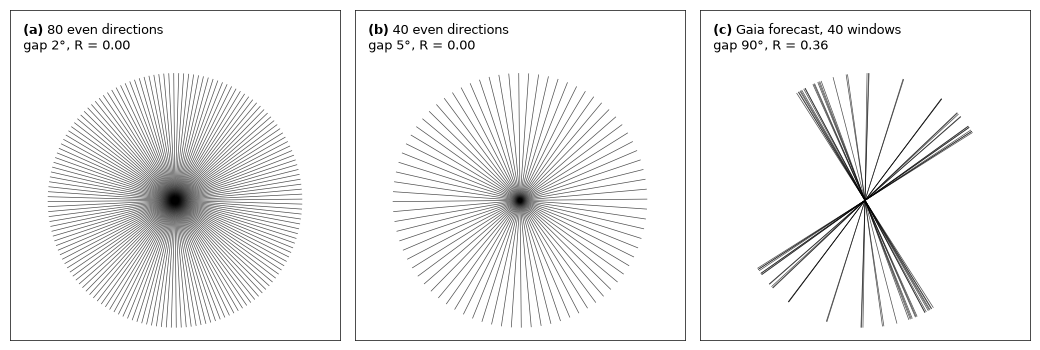

In [15]:
# The three sets on the half-turn, with their largest gap and anisotropy. Each direction is drawn as a line
# through the center, modulo 180 deg: the subject is the coverage of the half-turn
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.7), subplot_kw={"aspect": "equal"})
print(f"{'set':28s} {'n':>3s}  {'largest gap':>11s}  {'R':>5s}  dominant direction")
for ax, label, (name, psi) in zip(axes, "abc", LAWS):
    # R: the anisotropy of the set (0 to 1); direction: that of its dominant bundle [deg]; gap [deg]
    R, direction = anisotropy(psi)
    gap = largest_gap(psi)
    print(f"{name:28s} {psi.size:3d}  {gap:9.0f}°   {R:5.2f}  {direction:5.0f}°")
    # one line per direction, from -(sin, cos) to +(sin, cos) of its angle folded into the half-turn
    for folded_angle in np.mod(psi, np.pi):
        east = np.sin(folded_angle)
        north = np.cos(folded_angle)
        ax.plot([-east, east], [-north, north], color="k", lw=0.5, alpha=0.7)
    letter(ax, label, f"{name}\ngap {gap:.0f}°, R = {R:.2f}")
    ax.set(xlim=(1.3, -1.3), ylim=(-1.1, 1.5), xticks=[], yticks=[])   # as on the sky: north up, east to the left
plt.tight_layout()
plt.show()

## 2. The two images

*Paper: App. C.2, Eq. C.3 (the inverse Radon transform) and its text on faststack; Fig. C.1 (the same pair on two scan laws). The trimming fraction α is not in the paper; it is Harrison's (2011) parameter.*

**What they assume.** The inverse Radon transform is a quadrature over
directions: it assumes the directions cover the half-turn, and weights each
by its share of it. faststack assumes that at every pixel enough windows
contribute samples free of the primary's light to set the first estimate
r₀; its trimming fraction α says how many of the lowest samples do so.

**What they return.** On the forecast the inverse Radon transform's image
of a point source, its beam, grows streaks along the scanned bundles: the
largest excursion farther than 1.5 FWHM from the source is 0.29 of the peak,
against 0.01 on 80 even directions, and the primary's streaks run across the
companion. faststack's stars become the polygons their few strips cut out,
with spikes along the scanned directions at any α; on even coverage the
image is clean at α = 0.05 but at α = 0.45 a halo returns around the
primary, because at a pixel 150 to 300 mas from it about a fifth of the
strips hold the primary's light and α = 0.45 admits them to r₀. Harrison
(2011) recommends a low α for low or uneven coverage; here it is the only
choice on the forecast and the safe one on even coverage.

**Do they warn.** No. The streaks and spikes look like structure.

In [16]:
# the beam: the inverse Radon image of one source of flux 1000 at the origin, on the 80 even directions and on
# the forecast (LAWS[::2] takes every second entry, so it omits the 40 even directions), and its largest
# excursion farther than 1.5 FWHM from the source. `far` is the mask of those pixels; `far_both` also
# excludes the pixels within 150 mas of the companion
# step 1, the sky grid of the images: the coordinate of the rows and of the columns, and of every pixel [mas]
axis = np.arange(-half, half + 1e-9, step)
sky_x, sky_y = np.meshgrid(axis, axis)
far = np.hypot(sky_x, sky_y) > 1.5 * FWHM

# step 2, the beam of each of the two laws
for name, psi in LAWS[::2]:
    # the noise-free window of one source of flux 1000 at eta = 0; it is the same at every scan angle, so the
    # windows are that one window repeated, one row per scan
    source_window = ins.render_window([0.0], [1000.0], inst)
    source_windows = np.tile(source_window, (psi.size, 1))
    # radon.filtered_backprojection returns the image and its axis (dropped here, the name _)
    beam, _ = radon.filtered_backprojection(psi, source_windows, inst, half, step)
    largest_excursion = np.abs(beam[far]).max() / beam.max()
    print(f"beam, {name:28s}: largest excursion beyond 1.5 FWHM {largest_excursion:.3f} of the peak")

# step 3, the pixels far from both stars; theta[0] is the companion's dra*, theta[1] its ddec
far_both = far & (np.hypot(sky_x - theta[0], sky_y - theta[1]) > 150.0)

beam, 80 even directions          : largest excursion beyond 1.5 FWHM 0.011 of the peak
beam, Gaia forecast, 40 windows   : largest excursion beyond 1.5 FWHM 0.290 of the peak


faststack, 80 even directions           alpha = 0.05:    0 pixels far from both stars above 20 flux per sample (a tenth of the companion's level)
faststack, 80 even directions           alpha = 0.45:  437 pixels far from both stars above 20 flux per sample (a tenth of the companion's level)
faststack, Gaia forecast, 40 windows    alpha = 0.05:   21 pixels far from both stars above 20 flux per sample (a tenth of the companion's level)
faststack, Gaia forecast, 40 windows    alpha = 0.45:  161 pixels far from both stars above 20 flux per sample (a tenth of the companion's level)


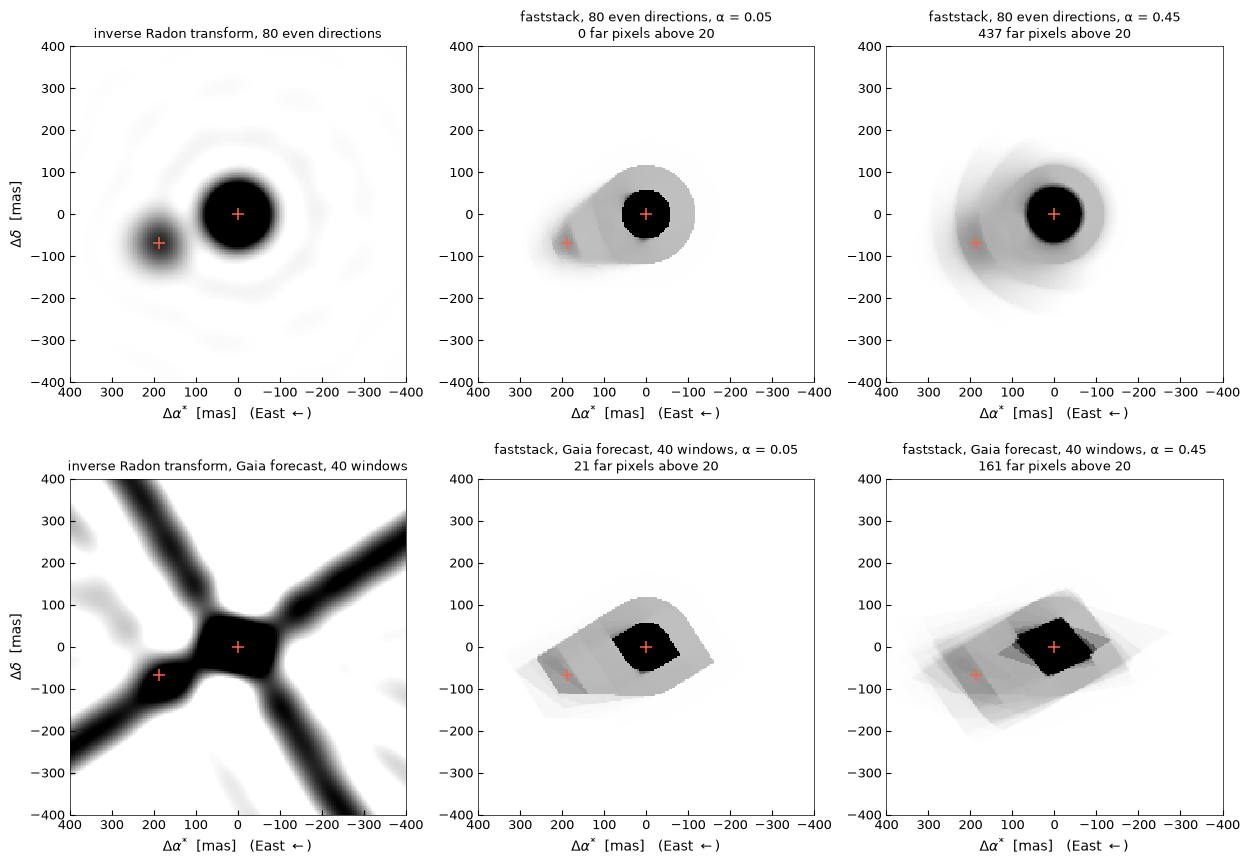

In [17]:
# the images of the pair on the two laws: the inverse Radon transform, and faststack at alpha = 0.05 and 0.45
# ([0] keeps the image of the four things radon.faststack returns), with the count of bright pixels far from
# both stars
fig, axes = plt.subplots(2, 3, figsize=(12.6, 8.8))
for row, (name, psi) in zip(axes, LAWS[::2]):
    # step 1, the noise-free windows of the pair on this law, and their inverse Radon image (its axis is dropped,
    # the name _: the page's `axis` is used)
    wins = windows_of(theta, psi)
    image, _ = radon.filtered_backprojection(psi, wins, inst, half, step)
    show(row[0], image, axis, f"inverse Radon transform, {name}", vmax=0.02)

    # step 2, faststack at two values of alpha, in the row's second and third panel (row[1:])
    for ax, alpha in zip(row[1:], (0.05, 0.45)):
        stack = radon.faststack(psi, wins, inst, half, step, alpha=alpha)[0]
        n_far = int(np.sum(stack[far_both] > 20.0))
        print(f"faststack, {name:28s} alpha = {alpha:.2f}: {n_far:4d} pixels far from both stars above 20 flux "
              f"per sample (a tenth of the companion's level)")
        show(ax, stack, axis, f"faststack, {name}, α = {alpha}\n{n_far} far pixels above 20", vmax=250)
    row[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 3. The map of detections

*Paper: Sect. 3.3, Eq. 13 (the map); Fig. C.1, panels d and h (the map on two scan laws); App. B.2 (only the windows that resolve the pair count).*

**What it assumes.** The crossing of the lines is sharp across the
directions that were scanned; the map assumes those directions surround the
source.

**What it returns.** A window resolves the companion only when the two
profiles are apart along the scan, η₂ − η₁ = ρ cos(ψ − φ): the scans near
the pair axis resolve it, the scans across the pair do not. The closer the
pair, the narrower the range of scan angles that resolves it, and the more
the law's gaps matter.

**The table** counts this for three separations, 60, 100 and 200 mas, on
the two laws. A window is *resolved* when the Fisher error of the
companion's along-scan position in it is finite and at most 30 mas. The
*directions spanned* are 180° minus the widest gap between the resolved
scan angles. On 80 even directions a pair at 60 mas is still resolved in
66 windows over 146°. On the forecast the same pair is resolved in 21
windows over 57°, all in one bundle.

**The figure** shows three maps, with the two sources as plus signs and
the map's peak as an open circle. The first is the reference: the control
pair at 200 mas on 80 even directions, 76 lines from all around, a round
peak with half-widths 7 and 9 mas. The second is the same pair on the
forecast: 33 lines over 90°, and the peak is stretched along the direction
no window measured, 5 mas across and 23 mas along. The third is a pair at
60 mas on the forecast: 21 lines in one bundle, the peak 7 mas across and
69 mas along, ten times longer, and its center 19 mas from the truth,
because along the bundle the lines barely constrain it (limitation
notebook 3 follows this case to its end).

**Does it warn.** Partly: `bp.map_peak` reports the width across, the narrow
one; the long axis is visible in the map and not in the number.

In [18]:
# the resolved windows per law and separation: sigma_windows is the Fisher error of the companion in each window
# (sigma_eta returns one value per companion; [0] takes the only one), `resolved` the mask of the resolved
# windows: those with a finite error of at most 30 mas, the limit of the teaching detections
print(f"{'rho [mas]':>9s}  {'set':28s}  resolved windows   directions spanned")
for rho in (60.0, 100.0, 200.0):
    companion = pair(rho)
    for name, psi in LAWS[::2]:
        sigma_windows = []
        for eta_j in joint.scene_positions_al(companion, psi):
            sigma_windows.append(sigma_eta(eta_j)[0])
        sigma_windows = np.array(sigma_windows)
        resolved = np.isfinite(sigma_windows) & (sigma_windows <= 30.0)
        # the directions spanned: the half-turn minus the largest gap of the resolved windows' directions
        spanned = 180 - largest_gap(psi[resolved])
        print(f"{rho:9.0f}  {name:28s}  {resolved.sum():3d} of {psi.size:2d}          {spanned:5.0f}°")

rho [mas]  set                           resolved windows   directions spanned
       60  80 even directions             66 of 80            146°
       60  Gaia forecast, 40 windows      21 of 40             57°
      100  80 even directions             72 of 80            160°
      100  Gaia forecast, 40 windows      29 of 40             90°
      200  80 even directions             76 of 80            169°
      200  Gaia forecast, 40 windows      33 of 40             90°


80 even directions, 200 mas: 76 lines; peak (187, -69) vs truth (188, -68); half-widths 7 across, 9 along
Gaia forecast, 200 mas: 33 lines; peak (188, -68) vs truth (188, -68); half-widths 5 across, 23 along
Gaia forecast, 60 mas: 21 lines; peak (67, -6) vs truth (56, -21); half-widths 7 across, 69 along


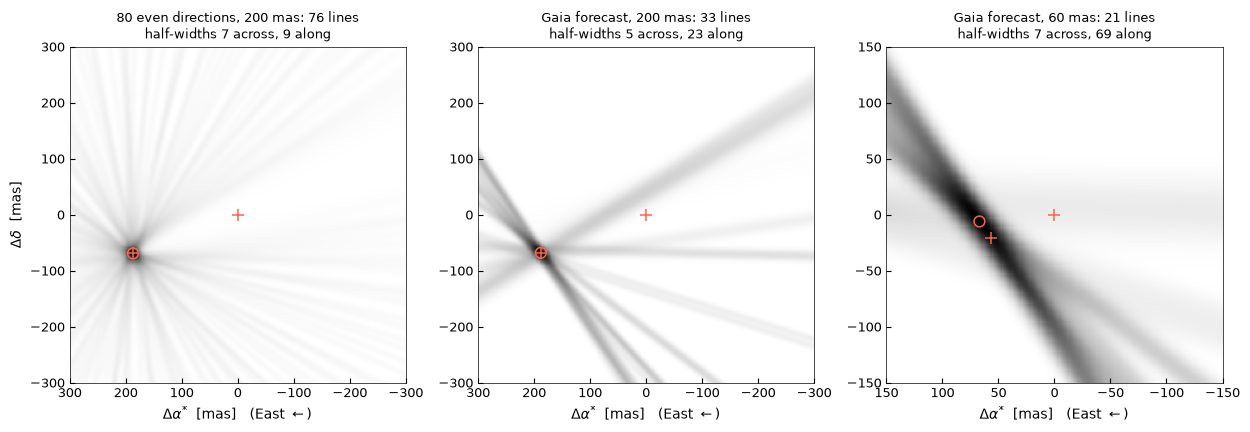

In [19]:
# three maps: the control pair on the even directions and on the forecast, and a pair at 60 mas on the
# forecast (on a smaller grid); the two sources (plus signs), the map's peak (open circle), and the peak's
# half-widths across and along
fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.5))
# one row per map: the name of the set of directions, its scan angles [rad], the pair's separation [mas] and
# the half-size of the map [mas]
MAPS = (("80 even directions", EVEN, 200.0, 300.0),
        ("Gaia forecast", GAIA, 200.0, 300.0),
        ("Gaia forecast", GAIA, 60.0, 150.0))
for ax, (name, psi, rho, half_map) in zip(axes, MAPS):
    # step 1, the teaching detections of the pair (the stand-in, not a reduction of windows), and their map's
    # peak with its two half-widths
    companion = pair(rho)
    d_psi, d_eta, d_sigma = detections(companion, psi)
    peak, (narrow, long_) = peak_axes(d_psi, d_eta, d_sigma, half_map)

    # step 2, the map itself, on a pixel of 1 mas. bp.backprojection_map returns the map, its axis, and the
    # extent for a picture (dropped here, the name _)
    sky_map, map_axis, _ = bp.backprojection_map(d_psi, d_eta, d_sigma, half_map, 1.0)
    print(f"{name}, {rho:.0f} mas: {d_psi.size} lines; peak ({peak[0]:.0f}, {peak[1]:.0f}) vs truth "
          f"({companion[0]:.0f}, {companion[1]:.0f}); half-widths {narrow:.0f} across, {long_:.0f} along")
    marks = np.vstack([[0.0, 0.0], companion])                # the primary at the origin, and the companion
    title = f"{name}, {rho:.0f} mas: {d_psi.size} lines\nhalf-widths {narrow:.0f} across, {long_:.0f} along"
    show(ax, sky_map, map_axis, title, marks)
    ax.scatter(*peak, **SEED)
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 4. The joint fit

*Paper: Sect. 4.3, Eq. 18 (the joint likelihood); App. B.2, Eq. B.9 (the position error for even coverage); App. B.3, Eq. B.13 (the proper-motion error). The pairing of angles and epochs is not in the paper; it is here because a real scan law fixes it.*

**What it assumes.** Nothing about the law: the covariance is the inverse
Fisher matrix of whatever windows there are. The assumption is the
reader's, when a precision is forecast from the number of windows and the
span alone.

**What it returns.** For the control pair the position block of the
covariance is close to σ_η² [Σ (sin ψ, cos ψ)(sin ψ, cos ψ)ᵀ]⁻¹, the case
of the formula (a static position, its windows' errors nearly equal), so
its axes are σ_η √(2/n) / √(1 ± R): round on even directions, and on the
forecast an ellipse with axis ratio 1.49, against √((1 + R)/(1 − R)) =
1.46, long across
the dominant bundle, because the direction across a scan is the one that
scan does not measure. 40 even directions carry the same information as the
forecast's 40 windows, spread evenly. For a moving companion the epochs come
with the directions, each bundle at its own epochs, and the position and
proper-motion errors depend on that pairing: re-pairing the forecast's
epochs with its angles at random changes the proper-motion errors by about
15 % and the correlations by tenths, a modest effect for 40 windows, present,
and not predictable from n and the span.

**Does it warn.** Yes, in the covariance: the ellipse and the correlations
are reported. Nothing warns in χ², because nothing is wrong with the model.

**The figure** draws covariance ellipses at Mahalanobis radius 1 (the
1σ of panel a), which in two dimensions enclose 39.3 % of the probability,
not 68 % ([conventions](../../../docs/conventions.md)).

set                           Fisher sigma (dra*, ddec) [mas]   ellipse axes [mas]   ratio   sqrt((1+R)/(1-R))
80 even directions            (0.77, 0.76)                      0.76, 0.77       1.01    1.00
40 even directions            (1.08, 1.07)                      1.07, 1.08       1.01    1.00
Gaia forecast, 40 windows     (1.36, 0.92)                      0.91, 1.36       1.49    1.46


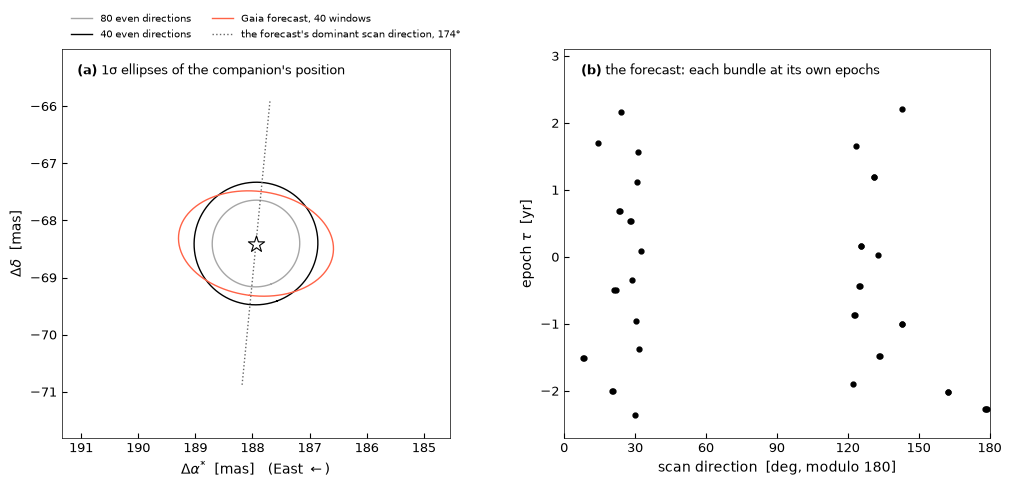

In [20]:
# (a) the 1-sigma ellipse of the control pair on the three sets, from the Fisher matrix of the joint fit
# (cov[:2, :2] is the position's 2 x 2 block), with the forecast's dominant scan direction dotted; (b) the
# forecast's epochs against its directions, modulo 180 deg: the subject is the bundles of the half-turn
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.9))
ax = axes[0]
print(f"{'set':28s}  Fisher sigma (dra*, ddec) [mas]   ellipse axes [mas]   ratio   sqrt((1+R)/(1-R))")
# step 1, (a): one ellipse per set of directions. The Fisher matrix is a formula at the truth: no windows, no
# fit and no noise draw
for (name, psi), color in zip(LAWS, ("0.65", "k", ACCENT)):
    # joint.joint_covariance(..., 2) returns the covariance of all the parameters and the 1-sigma of the first
    # two, the position; variances are those along the ellipse's two axes [mas^2], the smaller first
    fisher = joint.joint_fisher(theta, flux, psi, inst, sigma_noise)
    cov, sigma_position = joint.joint_covariance(fisher, 2)
    variances = np.linalg.eigvalsh(cov[:2, :2])
    short_axis = np.sqrt(variances[0])
    long_axis = np.sqrt(variances[1])
    axis_ratio = np.sqrt(variances[1] / variances[0])
    # R: the anisotropy of the set; sqrt((1 + R) / (1 - R)) is the axis ratio that R alone predicts
    R, direction = anisotropy(psi)
    predicted_ratio = np.sqrt((1 + R) / (1 - R))
    print(f"{name:28s}  ({sigma_position[0]:.2f}, {sigma_position[1]:.2f})                      "
          f"{short_axis:.2f}, {long_axis:.2f}       {axis_ratio:.2f}    {predicted_ratio:.2f}")
    outline = ellipse(cov[:2, :2], theta)
    ax.plot(outline[:, 0], outline[:, 1], color=color, lw=1, label=name)

# step 2, the forecast's dominant scan direction: a dotted line through the companion, 2.5 mas to either side
R, direction = anisotropy(GAIA)
direction_rad = np.deg2rad(direction)
line_dra = theta[0] + 2.5 * np.array([-np.sin(direction_rad), np.sin(direction_rad)])
line_ddec = theta[1] + 2.5 * np.array([-np.cos(direction_rad), np.cos(direction_rad)])
ax.plot(line_dra, line_ddec, color="0.4", ls=":", lw=1,
        label=f"the forecast's dominant scan direction, {direction:.0f}°")
ax.scatter(*theta, **TRUTH)
ax.set(aspect="equal", xlabel=EAST, ylabel=NORTH)
ax.set_xlim(theta[0] + 3.4, theta[0] - 3.4)                       # east to the left
ax.set_ylim(theta[1] - 3.4, theta[1] + 3.4)
letter(ax, "a", "1σ ellipses of the companion's position")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2)

# step 3, (b): the forecast's epochs against its directions folded into the half-turn
axes[1].plot(np.degrees(np.mod(GAIA, np.pi)), GAIA_TAU, "ko", ms=3.5)
axes[1].set(xlabel="scan direction  [deg, modulo 180]", ylabel=r"epoch $\tau$  [yr]", xlim=(0, 180),
            xticks=np.arange(0, 181, 30), ylim=(-2.7, 3.1))
letter(axes[1], "b", "the forecast: each bundle at its own epochs")
plt.tight_layout()
plt.show()

In [21]:
# the moving fit's covariance with the forecast's pairing of epochs and angles, and with the epochs re-paired
# at random. np.r_ appends the proper motion (5, -3) mas/yr to the position; cov[:4, :4] is the block of the
# four astrometric parameters, without the fluxes
theta_moving = np.r_[theta, 5.0, -3.0]                        # (dra*, ddec [mas], mu_alpha*, mu_delta [mas/yr])
names = ("Δα*", "Δδ", "μα*", "μδ")
# rng_pairing: seed 12, the one random order of the forecast's epochs against its scan angles
rng_pairing = np.random.default_rng(12)
tau_repaired = rng_pairing.permutation(GAIA_TAU)
for name, tau in (("the forecast's pairing", GAIA_TAU), ("epochs re-paired at random", tau_repaired)):
    # the Fisher covariance at the truth (a formula: no windows and no fit), and the 1-sigma of the four
    # astrometric parameters
    fisher = joint.joint_fisher(theta_moving, flux, GAIA, inst, sigma_noise, tau=tau)
    cov, sigma_astrometric = joint.joint_covariance(fisher, 4)
    cov_astrometric = cov[:4, :4]
    # the correlation matrix: each covariance over the product of the two sigmas. [0, 2] is position against
    # proper motion in right ascension, [1, 3] the same in declination
    variances = np.diag(cov_astrometric)
    corr = cov_astrometric / np.sqrt(np.outer(variances, variances))
    # each sigma as text behind its parameter's name (a short comprehension: one piece per parameter)
    sigma_text = ", ".join(f"{parameter} {sigma:.2f}" for parameter, sigma in zip(names, sigma_astrometric))
    print(f"moving fit, {name}: sigma {sigma_text}"
          f"; correlations (Δα*, μα*) {corr[0, 2]:+.2f}, (Δδ, μδ) {corr[1, 3]:+.2f}")

moving fit, the forecast's pairing: sigma Δα* 1.38, Δδ 1.00, μα* 1.13, μδ 0.66; correlations (Δα*, μα*) +0.18, (Δδ, μδ) +0.39
moving fit, epochs re-paired at random: sigma Δα* 1.41, Δδ 0.98, μα* 0.98, μδ 0.69; correlations (Δα*, μα*) +0.30, (Δδ, μδ) +0.35


## Summary

| atom | effect in this case | alarm | remedy |
|---|---|---|---|
| inverse Radon transform | streaks along the bundles, 0.29 of the peak beyond 1.5 FWHM against 0.01 on even directions | none | none; the forward fit needs no coverage of the half-turn |
| faststack | polygons and spikes along the bundles at any α; a halo at large α even on even coverage | none | a low α, 0.05, Harrison's recommendation |
| map of detections | the peak stretched along the unscanned direction; a close pair's lines all in one bundle | the width across is reported, the length along is not | read the map, not only the number; limitation notebook 3 |
| joint fit | ellipse axis ratio 1.49 on the forecast, close to √((1+R)/(1−R)) = 1.46 of a static position with equal errors; position and proper motion coupled through the angle-epoch pairing | the covariance reports both | none needed; forecast precision from the covariance, not from n and the span |

## What this establishes

- A set of directions has a largest gap and an anisotropy R, and they are
  not the same: the gap streaks the images and stretches the map, R
  elongates the error ellipse of a static position with equal errors by
  √((1 + R)/(1 − R)), long across the dominant bundle. Unequal errors,
  motion and parallax need the fit's own covariance.
- A close companion is resolved only by the scans near the pair axis. On an
  even law those still span the half-turn; on a clumped law they can fall in
  one bundle, and its lines cross at a shallow angle.
- faststack's α is free only on even coverage, and even there a large α
  brings the halo back; on the forecast the spikes are there at any α.
- The epochs come with the directions. The moving fit's covariance carries
  the pairing; a forecast from n and the span alone cannot.